### EDA y preparación de datos

In [ ]:
# Importación de librerias
import warnings
import random
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression

# Creación de dataframes

df_indian = pd.read_csv(Path("/content/Indian_housing_Mumbai_data.csv"))

df_indian.info()

# Analisis de nulos y duplicados

print(f"Total de duplicados: ", df_indian.duplicated().sum())

df_indian.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   house_type        5000 non-null   object 
 1   house_size        5000 non-null   object 
 2   location          5000 non-null   object 
 3   city              5000 non-null   object 
 4   latitude          5000 non-null   float64
 5   longitude         5000 non-null   float64
 6   price             5000 non-null   int64  
 7   currency          5000 non-null   object 
 8   numBathrooms      4986 non-null   float64
 9   numBalconies      733 non-null    float64
 10  isNegotiable      571 non-null    object 
 11  priceSqFt         0 non-null      float64
 12  verificationDate  5000 non-null   object 
 13  description       4922 non-null   object 
 14  SecurityDeposit   5000 non-null   object 
 15  Status            5000 non-null   object 
dtypes: float64(5), int64(1), object(10)
memory

,0
house_type,0
house_size,0
location,0
city,0
latitude,0
longitude,0
price,0
currency,0
numBathrooms,14
numBalconies,4267


In [ ]:
# Limpieza de nulos y duplicados

df_indian = df_indian.drop_duplicates()
print(f"Total de duplicados: ", df_indian.duplicated().sum())

# Conversión a número
def convertir_tamano(texto):
    if pd.isna(texto):
        return np.nan
    texto = texto.replace(' sq ft', '')
    texto = texto.replace(',', '')
    return float(texto)

df_indian['house_size'] = df_indian['house_size'].apply(convertir_tamano)
df_indian['latitude'] = pd.to_numeric(df_indian['latitude'], errors='coerce')
df_indian['longitude'] = pd.to_numeric(df_indian['longitude'], errors='coerce')

# Dataframe copia para la imputación de datos

df_temp = df_indian.copy()

df_temp['numBathrooms'] = df_temp['numBathrooms'].fillna(df_temp['numBathrooms'].median())

df_temp['numBalconies'] = df_temp['numBalconies'].fillna(df_temp['numBalconies'].median())

df_temp['isNegotiable'] = df_temp['isNegotiable'].fillna("Not Negotiables")

df_temp['priceSqFt'] = df_temp['priceSqFt'].fillna(0)

df_temp['description'] = df_temp['description'].fillna("Not Description")

df_temp.isna().sum()

Total de duplicados:  0


,0
house_type,0
house_size,0
location,0
city,0
latitude,0
longitude,0
price,0
currency,0
numBathrooms,0
numBalconies,0


   1. price (1.000)
   2. house_size (0.732)
   3. numBathrooms (0.580)
   4. numBalconies (0.107)
   5. longitude (-0.087)
   6. latitude (-0.100)
   7. priceSqFt (nan)


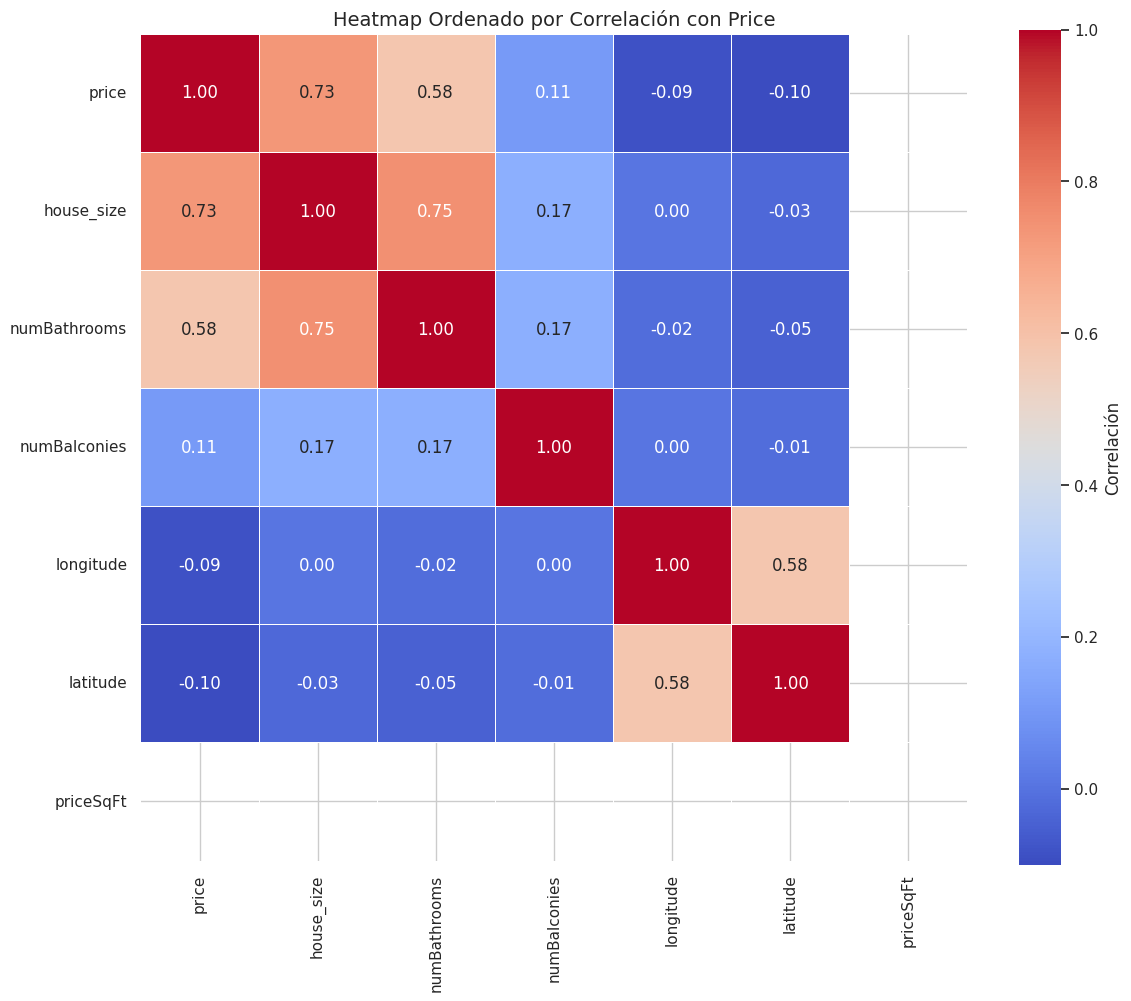

In [ ]:
# Matriz de correlación

matriz = df_temp.corr(numeric_only=True)

correlacion = matriz['price'].sort_values(ascending=False)
orden = correlacion.index.to_list()

for i, col in enumerate(orden, 1):
    corr = correlacion[col]
    print(f"   {i}. {col} ({corr:.3f})")

matriz_nueva = matriz[orden].loc[orden]

plt.figure(figsize=(12, 10))
sns.heatmap(matriz_nueva,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5,
            square=True,
            cbar_kws={'label': 'Correlación'})
plt.title('Heatmap Ordenado por Correlación con Price', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# Eliminación de columnas innecesarias

eliminar = [
    'house_type',
    'location',
    'numBalconies',
    'city',
    'currency',
    'isNegotiable',
    'priceSqFt',
    'description',
    'SecurityDeposit',
    'verificationDate',
    'Status'
]

df_indian = df_indian.drop(columns=eliminar, errors='i ')

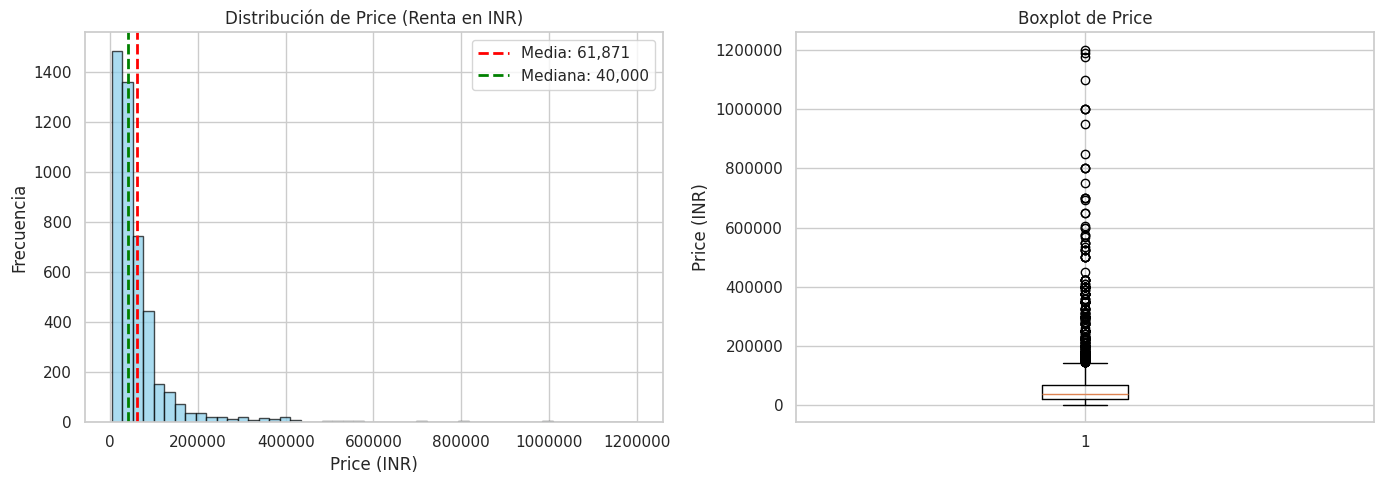

In [ ]:
# Analisis de la variable objetivo (price)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Histograma
axes[0].hist(df_indian['price'], bins=50, edgecolor='black', alpha=0.7, color='skyblue')
axes[0].axvline(df_indian['price'].mean(), color='red', linestyle='dashed', linewidth=2, label=f'Media: {df_indian["price"].mean():,.0f}')
axes[0].axvline(df_indian['price'].median(), color='green', linestyle='dashed', linewidth=2, label=f'Mediana: {df_indian["price"].median():,.0f}')
axes[0].set_title('Distribución de Price (Renta en INR)')
axes[0].set_xlabel('Price (INR)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()
axes[0].ticklabel_format(style='plain', axis='x')

# Gráfico 2: Boxplot
axes[1].boxplot(df_indian['price'])
axes[1].set_title('Boxplot de Price')
axes[1].set_ylabel('Price (INR)')
axes[1].ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()


 house_size:
Q1: 650.00
Q3: 1200.00
IQR: 550.00
Límite inferior: -175.00
Límite superior: 2025.00
Outliers: 180 (3.9%)

 price:
Q1: 21400.00
Q3: 70000.00
IQR: 48600.00
Límite inferior: -51500.00
Límite superior: 142900.00
Outliers: 338 (7.3%)

 latitude:
Q1: 19.07
Q3: 19.20
IQR: 0.13
Límite inferior: 18.88
Límite superior: 19.39
Outliers: 152 (3.3%)

 longitude:
Q1: 72.84
Q3: 72.99
IQR: 0.15
Límite inferior: 72.61
Límite superior: 73.22
Outliers: 41 (0.9%)

 numBathrooms:
Q1: 2.00
Q3: 2.00
IQR: 0.00
Límite inferior: 2.00
Límite superior: 2.00
Outliers: 1909 (41.2%)


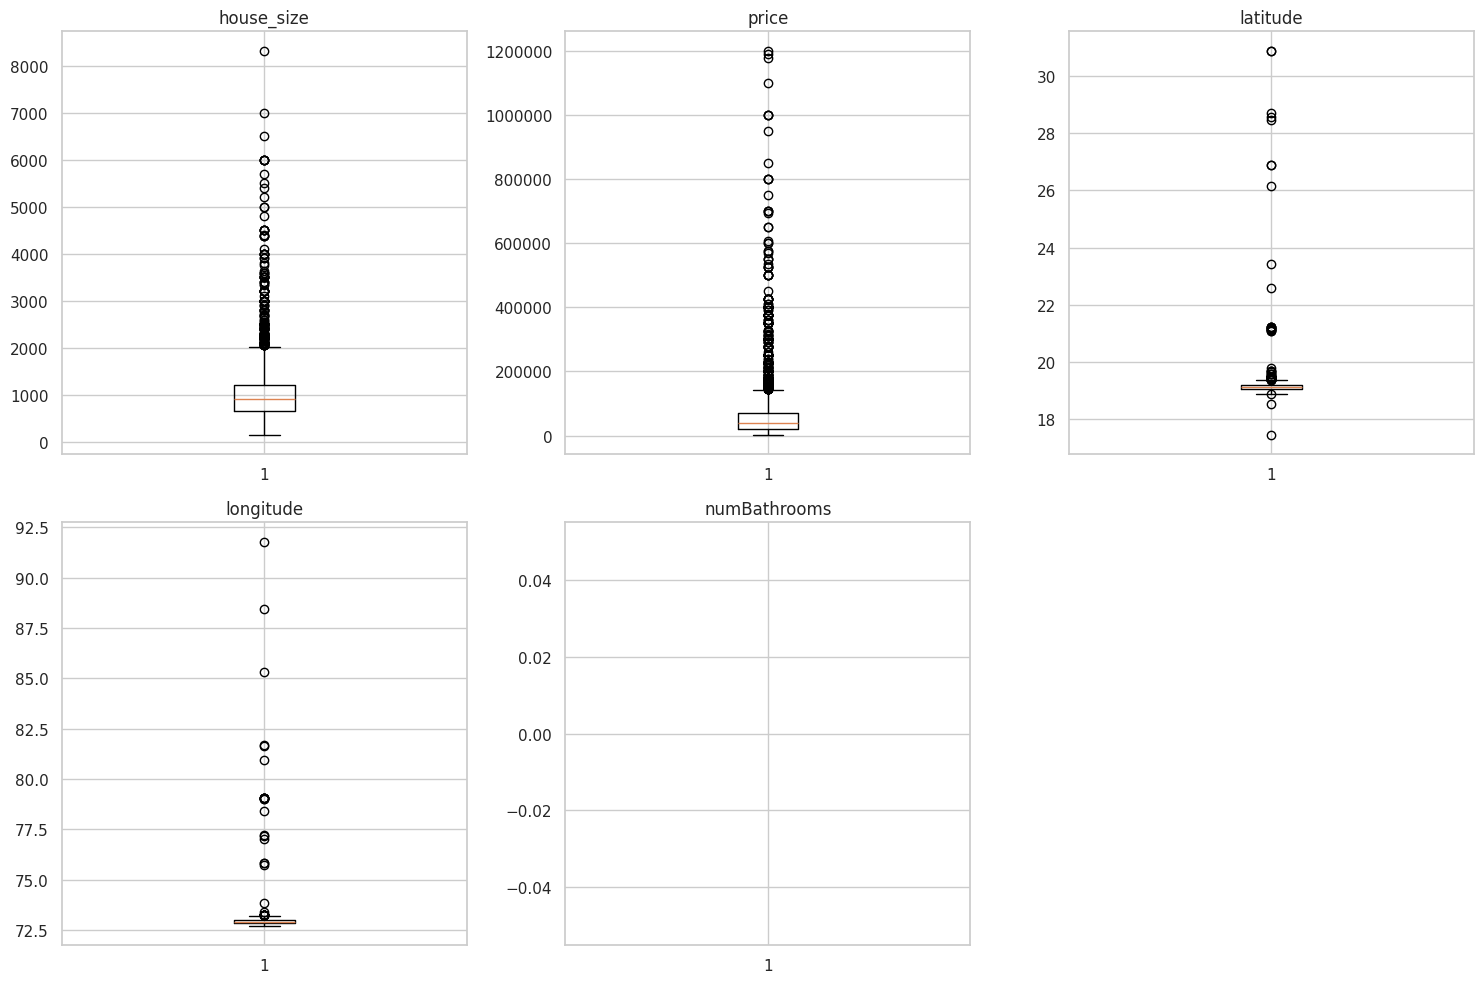

In [ ]:
# Detección de Outliers

def outliers(df, columna):
  Q1 = df[columna].quantile(0.25)
  Q3 = df[columna].quantile(0.75)
  IQR = Q3 - Q1
  limite_inferior = Q1 - 1.5 * IQR
  limite_superior = Q3 + 1.5 * IQR

  outliers = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)]

  return {
      'columna': columna,
      'Q1': Q1,
      'Q3': Q3,
      'IQR': IQR,
      'limite_inferior': limite_inferior,
      'limite_superior': limite_superior,
      'n_outliers': len(outliers),
      'porcentaje': len(outliers) / len(df) * 100
  }

# Columnas numéricas a analizar

numerico = ['house_size' ,'price', 'latitude', 'longitude', 'numBathrooms']

resultados = []

for col in numerico:
  if col in df_indian.columns:
    resul = outliers(df_indian, col)
    resultados.append(resul)
    print(f"\n {col}:")
    print(f"Q1: {resul['Q1']:.2f}")
    print(f"Q3: {resul['Q3']:.2f}")
    print(f"IQR: {resul['IQR']:.2f}")
    print(f"Límite inferior: {resul['limite_inferior']:.2f}")
    print(f"Límite superior: {resul['limite_superior']:.2f}")
    print(f"Outliers: {resul['n_outliers']} ({resul['porcentaje']:.1f}%)")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, col in enumerate(numerico):
  if col in df_indian.columns:
    axes[i//3, i%3].boxplot(df_indian[col])
    axes[i//3, i%3].set_title(col)
    axes[i//3, i%3].ticklabel_format(style='plain', axis='y')

if len(numerico) < 6:
  axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

Total de duplicados:  608
Total de duplicados:  0
Skewness de price: 5.58
Skewness de price_log (transformado): 0.21


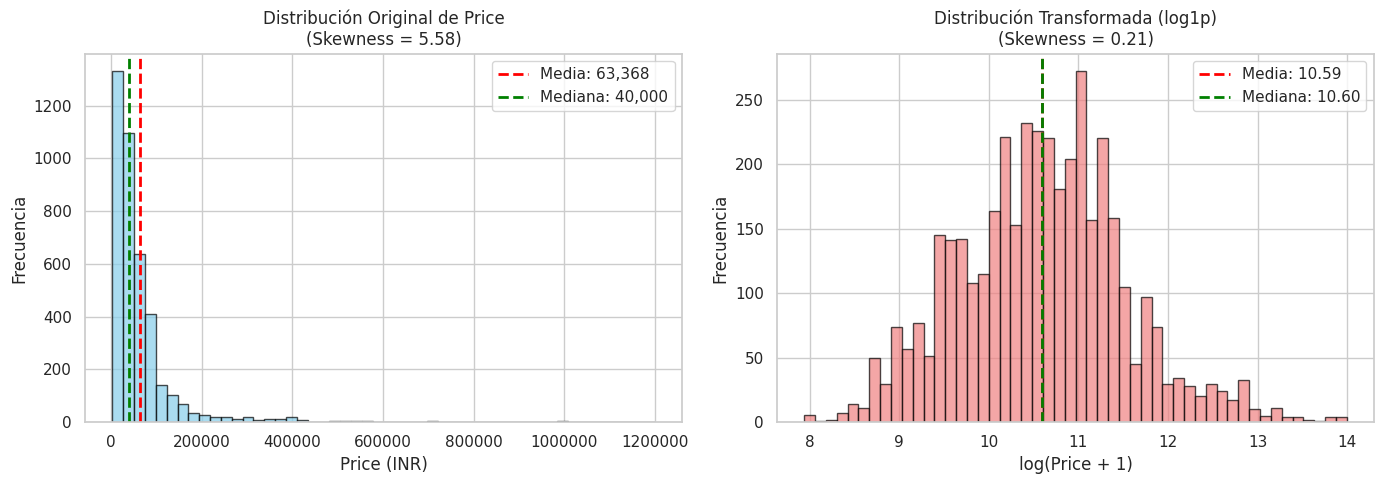

In [ ]:
# Verificación de duplicados, limpieza de valores nulos y balanceo

df_indian['numBathrooms'] = df_indian['numBathrooms'].fillna(df_indian['numBathrooms'].median())

print(f"Total de duplicados: ", df_indian.duplicated().sum())

df_indian = df_indian.drop_duplicates()
print(f"Total de duplicados: ", df_indian.duplicated().sum())

# Balanceo

# Calcular skewness de price
skewness = df_indian['price'].skew()
print(f"Skewness de price: {skewness:.2f}")

# Se aplica la transformación logaritmica

df_indian['price_log'] = np.log1p(df_indian['price'])
skewness_log = df_indian['price_log'].skew()
print(f"Skewness de price_log (transformado): {skewness_log:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_indian['price'], bins=50, edgecolor='black', alpha=0.7, color='skyblue')
axes[0].axvline(df_indian['price'].mean(), color='red', linestyle='dashed', linewidth=2,
                label=f'Media: {df_indian["price"].mean():,.0f}')
axes[0].axvline(df_indian['price'].median(), color='green', linestyle='dashed', linewidth=2,
                label=f'Mediana: {df_indian["price"].median():,.0f}')
axes[0].set_title('Distribución Original de Price\n(Skewness = 5.58)')
axes[0].set_xlabel('Price (INR)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()
axes[0].ticklabel_format(style='plain', axis='x')

axes[1].hist(df_indian['price_log'], bins=50, edgecolor='black', alpha=0.7, color='lightcoral')
axes[1].axvline(df_indian['price_log'].mean(), color='red', linestyle='dashed', linewidth=2,
                label=f'Media: {df_indian["price_log"].mean():.2f}')
axes[1].axvline(df_indian['price_log'].median(), color='green', linestyle='dashed', linewidth=2,
                label=f'Mediana: {df_indian["price_log"].median():.2f}')
axes[1].set_title('Distribución Transformada (log1p)\n(Skewness = 0.21)')
axes[1].set_xlabel('log(Price + 1)')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()

plt.tight_layout()
plt.show()

### Red neuronal MLP

In [ ]:
# Semilla utilizada para que la división sea siempre la misma
RANDOM_STATE = 42

# Las 4 variables seleccionadas en el EDA
variables_seleccionadas = [
    'house_size',
    'latitude',
    'longitude',
    'numBathrooms'
]

# X contiene las variables que usará la red para hacer la predicción
X = df_indian[variables_seleccionadas]

# y contiene el precio que queremos predecir
y = df_indian['price_log']

print('Variables de entrada:', variables_seleccionadas)
print('Variable objetivo: price_log')

Variables de entrada: ['house_size', 'latitude', 'longitude', 'numBathrooms']
Variable objetivo: price_log


Se utiliza exactamente la misma configuracion para todo el proyecto:

- 88% para entrenamiento.
- 12% para prueba.
- `RANDOM_STATE = 42`.

El conjunto de prueba se mantiene separado y no se utiliza para entrenar la red.

In [ ]:
# Dividir los datos en 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.12,
    random_state=RANDOM_STATE
)

print('Datos de entrenamiento:', len(X_train))
print('Datos de prueba:', len(X_test))

#ajustamos los datos con el escalador

# Crear el escalador
scaler = StandardScaler()

# Ajustar el escalador usando solamente entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Aplicar la misma transformación a prueba
X_test_scaled = scaler.transform(X_test)

Datos de entrenamiento: 3538
Datos de prueba: 483


Creacion de red neuronal

**4 entradas → 64 neuronas → 32 neuronas → 1 salida**

Las capas ocultas utilizan ReLU para aprender relaciones no lineales.

La última capa tiene una sola neurona porque queremos predecir un único valor: el precio.

Se utiliza Adam como optimizador y MSE como función de pérdida.

El MSE mide qué tan diferentes son las predicciones del precio real.

In [ ]:
# Creamos la red neuronal
model = Sequential([
    Dense(64, activation='relu', input_shape=(4,)),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

# Mostrar la estructura de la red
model.summary()

#compilacion del modelo

# Configurar el entrenamiento de la red
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mse']
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,433 (9.50 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

se entrenara al modelo por 200 epocas



In [ ]:
#para el entrenamiento en caso de que no mejore la validacion
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

# Entrenar la red neuronal por 200 epocas como maximo
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)
#al final si se detiene antes se queda con los mejores pesos

Epoch 1/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 82.8487 - mse: 82.8487 - val_loss: 37.5041 - val_mse: 37.5041
Epoch 2/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 17.4437 - mse: 17.4437 - val_loss: 6.8486 - val_mse: 6.8486
Epoch 3/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.7903 - mse: 4.7903 - val_loss: 2.6721 - val_mse: 2.6721
Epoch 4/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.0010 - mse: 2.0010 - val_loss: 1.2204 - val_mse: 1.2204
Epoch 5/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.9860 - mse: 0.9860 - val_loss: 0.6459 - val_mse: 0.6459
Epoch 6/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5406 - mse: 0.5406 - val_loss: 0.4220 - val_mse: 0.4220
Epoch 7/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3818 - mse: 0.3818 - val_loss: 0.3269 - val_mse: 0.3269
Epoch 8/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3003 - mse: 0.3003 - val_loss: 0.2564 - val_mse: 0.2564
Epoch 9/200
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss:

Gráfica del MSE

Se muestran los errores de entrenamiento y validación durante las épocas.

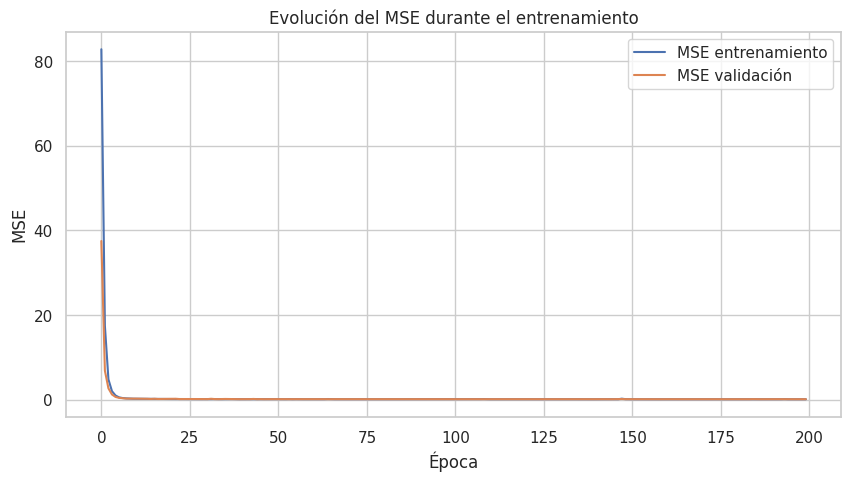

MSE mínimo de entrenamiento: 0.09628841280937195
Época del MSE mínimo de entrenamiento: 200

MSE mínimo de validación: 0.10025732219219208
Época del MSE mínimo de validación: 180


In [ ]:
# Obtener los valores de MSE guardados durante el entrenamiento
mse_entrenamiento = history.history['mse']
mse_validacion = history.history['val_mse']

# Graficar la evolución del error
plt.figure(figsize=(10, 5))

plt.plot(mse_entrenamiento, label='MSE entrenamiento')
plt.plot(mse_validacion, label='MSE validación')

plt.xlabel('Época')
plt.ylabel('MSE')
plt.title('Evolución del MSE durante el entrenamiento')
plt.legend()
plt.grid(True)
plt.show()

# Obtener los mejores valores de MSE
mse_train_min = min(mse_entrenamiento)
mse_val_min = min(mse_validacion)

epoca_train = np.argmin(mse_entrenamiento) + 1
epoca_val = np.argmin(mse_validacion) + 1

print(f'MSE mínimo de entrenamiento: {mse_train_min}')
print(f'Época del MSE mínimo de entrenamiento: {epoca_train}')

print(f'\nMSE mínimo de validación: {mse_val_min}')
print(f'Época del MSE mínimo de validación: {epoca_val}')

Finalmente se evalúa la red con los datos de prueba.

In [ ]:
# Evaluar el modelo con los datos de prueba
test_loss, test_mse = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f'MSE final en testing: {test_mse:.2f}')

# Guardar el MSE para utilizarlo en la comparación final
mse_mlp = test_mse

# Generar predicciones
y_pred = model.predict(X_test_scaled, verbose=0).flatten()

# Mostrar algunos resultados
resultados = pd.DataFrame({
    'Precio real': y_test.values[:10],
    'Precio predicho': y_pred[:10]
})

resultados

MSE final en testing: 0.11


,Precio real,Precio predicho
0,11.608245,11.336400
1,9.680344,9.686162
2,9.615872,9.629644
3,10.085851,10.051631
4,10.859018,11.133277
5,11.695255,11.939802
6,10.657283,10.588067
7,12.899222,12.963128
8,9.472782,9.275456
9,9.798183,9.723277


Gráfica de precios reales vs. predichos

Esta gráfica permite observar visualmente qué tan cerca están las predicciones de los precios reales y el calculo final del MSE.

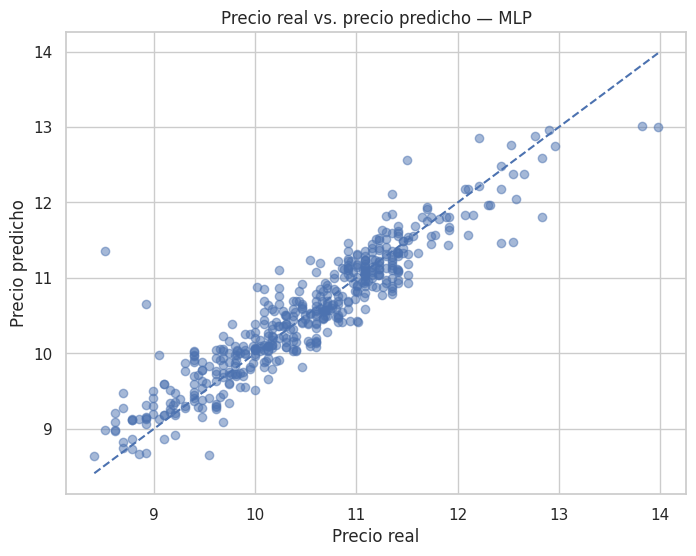

MSE final calculado: 0.11


In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Crear una línea diagonal de referencia
limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle='--'
)

plt.xlabel('Precio real')
plt.ylabel('Precio predicho')
plt.title('Precio real vs. precio predicho — MLP')
plt.grid(True)
plt.show()

# Calcular el MSE directamente
mse_final = mean_squared_error(y_test, y_pred)

print(f'MSE final calculado: {mse_final:,.2f}')

### Modelo de Ensemble Learning


Para abordar la predicción del precio de los inmuebles, se selecciona el enfoque de Ensemble Learning por Boosting mediante el algoritmo GradientBoostingRegressor. Esta elección se fundamenta en que Boosting entrena árboles de decisión de forma secuencial, donde cada nuevo árbol enfoca su aprendizaje en corregir los residuos (errores) del árbol anterior.

Dado que el objetivo prioritario del proyecto es minimizar el Error Cuadrático Medio ($MSE$), Boosting resulta superior a otras técnicas (como Bagging o Voting) al optimizar directamente la función de pérdida paso a paso.

Además, permite capturar patrones complejos no lineales interaccionados entre la ubicación geográfica (latitude, longitude) y el tamaño de la propiedad (house_size), logrando una mayor precisión en el conjunto de prueba.

=== EVALUACIÓN DEL MODELO DE ENSAMBLE ===
Registros Entrenados (88%): 3538
Registros Evaluación (12%): 483
-------------------------------------------------------
MSE Train (Boosting): 0.07
MSE Test  (Boosting): 0.08
RMSE Test (Boosting): $0.28
R² Score (Boosting) : 0.9032


--- TABLA COMPARATIVA ---


,Modelo,MSE Test,MAE Test,R² Score
0,Árbol Individual (Baseline),0.11,0.24,0.8698
1,Gradient Boosting (Ensamble),0.08,0.22,0.9032


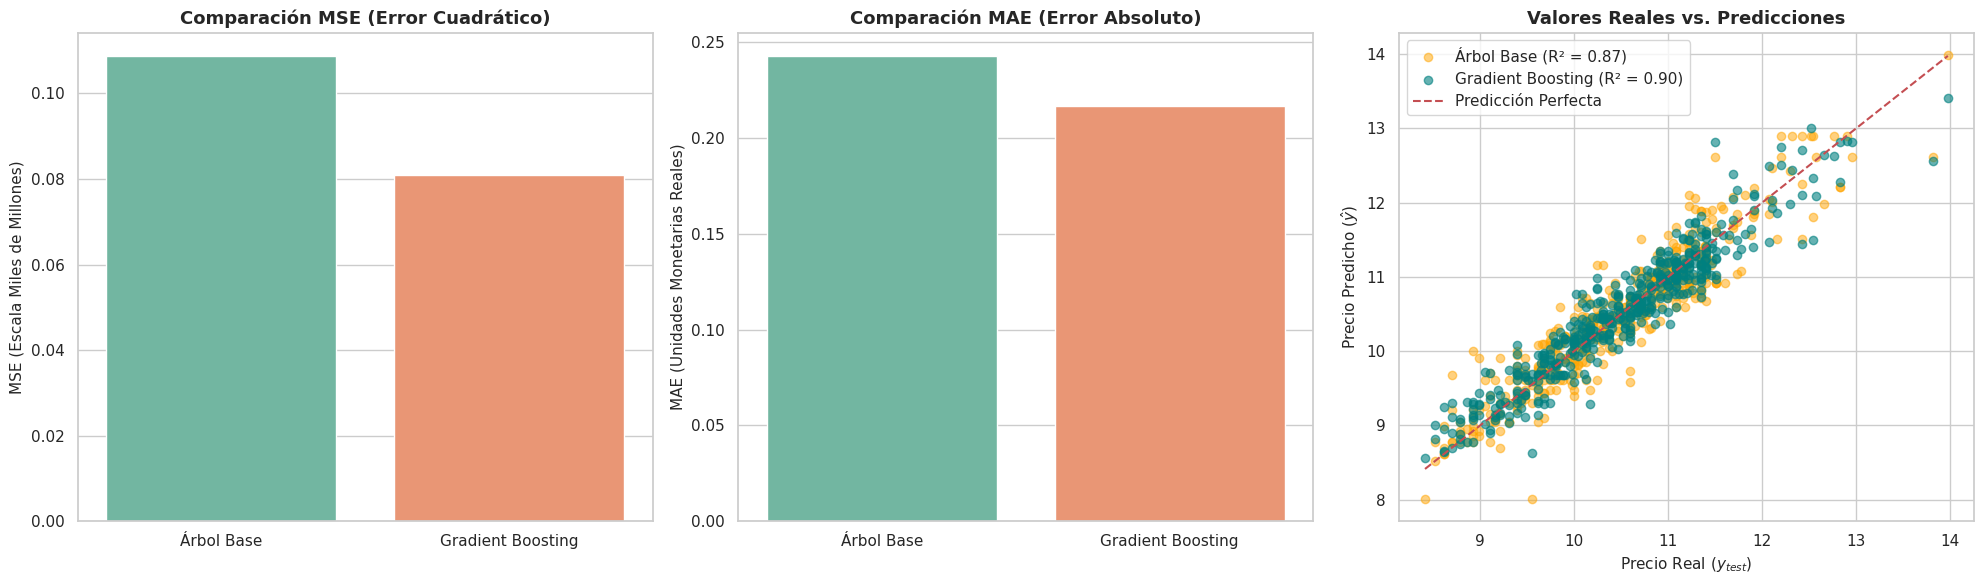

In [ ]:
warnings.filterwarnings('ignore') # silencia advertencia del sistema


# Entrenamiento

# 1. Modelo Baseline (Árbol Individual)
modelo_baseline = DecisionTreeRegressor(random_state=RANDOM_STATE)
modelo_baseline.fit(X_train_scaled, y_train)

# 2. Ensamble por Boosting (Gradient Boosting)
modelo_boosting = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)
modelo_boosting.fit(X_train_scaled, y_train)

# Prediccion y calculo de metricas

# Predicciones Baseline
y_pred_test_base = modelo_baseline.predict(X_test_scaled)

# Predicciones Boosting
y_pred_train_boost = modelo_boosting.predict(X_train_scaled)
y_pred_test_boost = modelo_boosting.predict(X_test_scaled)

# Métricas Baseline
mse_base = mean_squared_error(y_test, y_pred_test_base)
mae_base = mean_absolute_error(y_test, y_pred_test_base)
r2_base = r2_score(y_test, y_pred_test_base)

# Métricas Boosting
mse_train_boost = mean_squared_error(y_train, y_pred_train_boost)
mse_test_boost = mean_squared_error(y_test, y_pred_test_boost)
mae_test_boost = mean_absolute_error(y_test, y_pred_test_boost)
rmse_test_boost = np.sqrt(mse_test_boost)
r2_test_boost = r2_score(y_test, y_pred_test_boost)

# Resultados y tabla comparativa

print("=== EVALUACIÓN DEL MODELO DE ENSAMBLE ===")
print(f"Registros Entrenados (88%): {X_train.shape[0]}")
print(f"Registros Evaluación (12%): {X_test.shape[0]}")
print("-" * 55)
print(f"MSE Train (Boosting): {mse_train_boost:,.2f}")
print(f"MSE Test  (Boosting): {mse_test_boost:,.2f}")
print(f"RMSE Test (Boosting): ${rmse_test_boost:,.2f}")
print(f"R² Score (Boosting) : {r2_test_boost:.4f}")
print("\n")

tabla_comparativa = pd.DataFrame({
    'Modelo': ['Árbol Individual (Baseline)', 'Gradient Boosting (Ensamble)'],
    'MSE Test': [f"{mse_base:,.2f}", f"{mse_test_boost:,.2f}"],
    'MAE Test': [f"{mae_base:,.2f}", f"{mae_test_boost:,.2f}"],
    'R² Score': [f"{r2_base:.4f}", f"{r2_test_boost:.4f}"]
})

print("--- TABLA COMPARATIVA ---")
display(tabla_comparativa)

# Visualizacion y graficas

# Configuración de estilo
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# DataFrames separados para evitar distorsión de escala Y
df_mse = pd.DataFrame({
    'Modelo': ['Árbol Base', 'Gradient Boosting'],
    'MSE': [mse_base, mse_test_boost]
})

df_mae = pd.DataFrame({
    'Modelo': ['Árbol Base', 'Gradient Boosting'],
    'MAE': [mae_base, mae_test_boost]
})

# --- GRÁFICA 1: Comparativa de MSE ---
sns.barplot(
    data=df_mse,
    x='Modelo',
    y='MSE',
    ax=axes[0],
    palette='Set2'
)
axes[0].set_title('Comparación MSE (Error Cuadrático)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('MSE (Escala Miles de Millones)', fontsize=11)
axes[0].set_xlabel('', fontsize=11)

# --- GRÁFICA 2: Comparativa de MAE ---
sns.barplot(
    data=df_mae,
    x='Modelo',
    y='MAE',
    ax=axes[1],
    palette='Set2'
)
axes[1].set_title('Comparación MAE (Error Absoluto)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('MAE (Unidades Monetarias Reales)', fontsize=11)
axes[1].set_xlabel('', fontsize=11)

# --- GRÁFICA 3: Valores Reales vs Predichos ---
axes[2].scatter(y_test, y_pred_test_base, alpha=0.5, label=f'Árbol Base (R² = {r2_base:.2f})', color='orange')
axes[2].scatter(y_test, y_pred_test_boost, alpha=0.6, label=f'Gradient Boosting (R² = {r2_test_boost:.2f})', color='teal')

# Línea de predicción perfecta (y = x)
max_val = max(y_test.max(), y_pred_test_boost.max())
min_val = min(y_test.min(), y_pred_test_boost.min())
axes[2].plot([min_val, max_val], [min_val, max_val], 'r--', label='Predicción Perfecta')

axes[2].set_title('Valores Reales vs. Predicciones', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Precio Real ($y_{test}$)', fontsize=11)
axes[2].set_ylabel('Precio Predicho ($\hat{y}$)', fontsize=11)
axes[2].legend()

plt.tight_layout()
plt.show()

### Algoritmo genetico

Se implementa un algoritmo genetico **desde cero** para encontrar los coeficientes de un modelo de
regresion lineal que prediga el precio de renta. En lugar de resolver el problema por minimos
cuadrados, el algoritmo hace evolucionar una poblacion de vectores de coeficientes a lo largo de
varias generaciones y busca el conjunto de pesos que mejor ajusta los datos.



In [ ]:

# Columna de unos para que el intercepto sea un gen mas (theta_0)

X_train_ga = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]
X_test_ga = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]

y_train_ga =y_train.to_numpy(dtype=float)
y_test_ga = y_test.to_numpy(dtype=float)

print(f'Train: {X_train_ga.shape}   Test: {y_test_ga.shape}')

Train: (3538, 5)   Test: (483,)


### Regresion lineal de referencia

Antes de lanzar el algoritmo genetico se resuelve el mismo problema por **minimos cuadrados**. Sirve para saber cual es la respuesta correcta. Da los pesos optimos para este modelo y el MSE mas bajo que cualquier combinacion de coeficientes puede alcanzar.


Es importante ver que la pista es de **escala, no de posicion**: el algoritmo sabe que los
coeficientes son numeros de un digito o dos, pero no donde estan ni con que signo. La poblacion
inicial se sigue sorteando de forma uniforme por toda la caja, y el intercepto `10.6` esta tan lejos
del centro como cualquier otro punto.

In [ ]:
# Regresion lineal: solucion analitica del mismo modelo, usada como referencia y
# para fijar la escala del rango de busqueda del algoritmo genetico

from sklearn.linear_model import LinearRegression

# fit_intercept=False porque el intercepto ya es la primera columna (la de unos)
lin_reg = LinearRegression(fit_intercept=False)
lin_reg.fit(X_train_ga, y_train_ga)

pesos_referencia = pd.Series(lin_reg.coef_, index=['intercepto', *variables_seleccionadas])

print('Pesos optimos segun la regresion lineal:')
display(pesos_referencia.round(4))

mse_referencia = mean_squared_error(y_train_ga, lin_reg.predict(X_train_ga))
print(f'MSE de la regresion en entrenamiento: {mse_referencia:.6f}')
print('Ese es el suelo que el algoritmo genetico deberia alcanzar.\n')

Pesos optimos segun la regresion lineal:


,0
intercepto,10.5990
house_size,0.3385
latitude,-0.0546
longitude,-0.0991
numBathrooms,0.3265


MSE de la regresion en entrenamiento: 0.458939
Ese es el suelo que el algoritmo genetico deberia alcanzar.



### **PASO 1: INICIALIZACION**

Se crea una poblacion de soluciones. Cada solucion (individuo) es un grupo de **5 coeficientes**, uno
por cada columna de la matriz de features:

| gen | representa |
|---|---|
| `theta_0` | intercepto |
| `theta_1` | `house_size` |
| `theta_2` | `latitude` |
| `theta_3` | `longitude` |
| `theta_4` | `numBathrooms` |

In [ ]:
def initialize_poblation(size=100, semilla_min=-20, semilla_max=20, random_seed=42):
    np.random.seed(random_seed)
    random.seed(random_seed)

    # Los 5 genes (intercepto + 4 coeficientes) se sortean en el rango que fijo la regresion
    poblacion = np.random.uniform(semilla_min, semilla_max, size=(size, 5))

    poblacion = pd.DataFrame(poblacion,
                             columns=['theta_0', 'theta_1', 'theta_2', 'theta_3', 'theta_4'])
    poblacion['error'] = 0

    return poblacion


# Vista de la poblacion inicial (semilla aleatoria en el rango que dio la regresion)

poblacion_inicial = initialize_poblation()
cols_genes = ['theta_0', 'theta_1', 'theta_2', 'theta_3', 'theta_4']

print(f'Rango sorteado      : [{poblacion_inicial[cols_genes].values.min():.4f}, '
      f'{poblacion_inicial[cols_genes].values.max():.4f}]')
print('La columna "error" arranca en 0 porque el fitness aun no se ha evaluado.')

# max_rows=None evita que pandas trunque la tabla: por defecto recorta
# cualquier DataFrame de mas de 60 filas
with pd.option_context('display.max_rows', None):
    display(poblacion_inicial.round(4))

Rango sorteado      : [-19.7975, 19.7186]
La columna "error" arranca en 0 porque el fitness aun no se ha evaluado.


,theta_0,theta_1,theta_2,theta_3,theta_4,error
0,-5.0184,18.0286,9.2798,3.9463,-13.7593,0
1,-13.7602,-17.6767,14.6470,4.0446,8.3229,0
2,-19.1766,18.7964,13.2977,-11.5064,-12.7270,0
3,-12.6638,-7.8303,0.9903,-2.7222,-8.3508,0
4,4.4741,-14.4202,-8.3142,-5.3455,-1.7572,0
5,11.4070,-12.0130,0.5694,3.6966,-18.1420,0
6,4.3018,-13.1790,-17.3979,17.9554,18.6253,0
7,12.3359,-7.8154,-16.0931,7.3693,-2.3939,0
8,-15.1185,-0.1929,-18.6245,16.3728,-9.6488,0
9,6.5009,-7.5316,0.8027,1.8684,-12.6058,0


np.random.uniform(low, high, size)
Sortea números de una distribución uniforme continua: cualquier valor del intervalo [-20, 20) tiene la misma probabilidad de salir.

### **PASO 2: EVALUACION DEL FITNESS**

El fitness mide que tan buena es cada solucion. Se usa el **error cuadratico medio (MSE)** sobre
`price_log`: cuanto menor el MSE, mejor el individuo.

Toda la poblacion se evalua con una sola multiplicacion matricial `genes @ X.T`, donde cada fila del
resultado son las predicciones de un individuo sobre todas las muestras. Es mucho mas rapido que
recorrer los individuos uno por uno, algo que importa porque el escenario 3 evalua 1000 generaciones
de 300 individuos sobre los 3216 inmuebles de entrenamiento.

El objetivo esta fijado por la regresion: su MSE de **0.4579** es el suelo. La poblacion inicial
arranca con errores de decenas, asi que el fitness tiene que recorrer mas de dos ordenes de magnitud
antes de tocarlo.

In [ ]:
def fitness(individuos: pd.DataFrame, X: np.ndarray, y_real: np.ndarray):
    # Extraccion de los genes de toda la poblacion -> (n_individuos, n_genes)
    genes = individuos.drop('error', axis=1).to_numpy(dtype=float)

    # Cada fila de predicciones son las predicciones de un individuo
    predicciones = genes @ X.T                 # (n_individuos, n_muestras)

    # MSE de cada individuo
    errores = np.mean((y_real - predicciones) ** 2, axis=1)

    individuos = individuos.copy()
    individuos['error'] = errores

    return individuos


# Se evalua la misma poblacion inicial del Paso 1: la columna "error" pasa de 0 al MSE real

poblacion_evaluada = fitness(
    individuos=poblacion_inicial,
    X = X_train_ga,
    y_real=y_train_ga
)

# Vista descriptiva de la tabla. Se renombra cada gen con la variable que representa y
# se agregan columnas de apoyo. El DataFrame original conserva los nombres theta_0..theta_4
# porque el paso de cruce los necesita con ese nombre exacto.

nombres_descriptivos = {
    'theta_0': 'intercepto',
    'theta_1': 'coef_house_size',
    'theta_2': 'coef_latitude',
    'theta_3': 'coef_longitude',
    'theta_4': 'coef_numBathrooms',
    'error': 'MSE',
}

tabla_fitness = poblacion_evaluada.rename(columns=nombres_descriptivos)

# ranking: posicion del individuo segun su fitness (1 = mejor de los 100)
tabla_fitness['ranking'] = tabla_fitness['MSE'].rank(method='min').astype(int)

tabla_fitness.index.name = 'individuo'
tabla_fitness = tabla_fitness[['intercepto', 'coef_house_size', 'coef_latitude',
                               'coef_longitude', 'coef_numBathrooms', 'MSE', 'ranking']]

# max_rows/max_columns en None evita que pandas recorte la tabla ni a lo alto ni a lo ancho
with pd.option_context('display.max_rows', None, 'display.max_columns', None,
                       'display.width', 200):
    display(tabla_fitness.round(4))

,intercepto,coef_house_size,coef_latitude,coef_longitude,coef_numBathrooms,MSE,ranking
individuo,,,,,,,
0,-5.0184,18.0286,9.2798,3.9463,-13.7593,539.8298,38
1,-13.7602,-17.6767,14.6470,4.0446,8.3229,1070.1777,76
2,-19.1766,18.7964,13.2977,-11.5064,-12.7270,1162.7704,80
3,-12.6638,-7.8303,0.9903,-2.7222,-8.3508,796.0974,62
4,4.4741,-14.4202,-8.3142,-5.3455,-1.7572,449.8529,29
5,11.4070,-12.0130,0.5694,3.6966,-18.1420,852.2312,65
6,4.3018,-13.1790,-17.3979,17.9554,18.6253,451.7645,31
7,12.3359,-7.8154,-16.0931,7.3693,-2.3939,270.2234,10
8,-15.1185,-0.1929,-18.6245,16.3728,-9.6488,1007.4084,72


### **PASO 3: SELECCION**

Con la poblacion ya evaluada, se seleccionan los mejores individuos para formar la siguiente
generacion. Se usa **seleccion por elitismo**: se ordena por error ascendente y se toma la mitad
superior. A diferencia de un `head(50)` fijo, aqui el numero de elegidos depende del tamano de la
poblacion, de modo que los tres escenarios sean realmente distintos y no colapsen todos a 50.

In [ ]:
def best_50(poblacion: pd.DataFrame, n_elite: int = 50):
    ordered_poblation = poblacion.sort_values(by='error', ascending=True)
    top50 = ordered_poblation.head(n_elite)

    return top50

### **PASO 4: CRUCE (CROSSOVER)**

Se crean nuevas soluciones cruzando las seleccionadas por parejas. Una probabilidad `gamma` decide
que genes se intercambian entre los dos padres. Con `gamma = 0.6`:

- si el numero aleatorio es **menor o igual** a 0.6, se intercambian `theta_0`, `theta_2` y `theta_4`
  (intercepto, `latitude` y `numBathrooms`);
- si es **mayor**, se intercambian `theta_1` y `theta_3` (`house_size` y `longitude`).

Los dos grupos son complementarios: cada gen pertenece a uno y solo uno, asi que ningun coeficiente
queda fuera del cruce. Al pasar de 4 a 5 genes con el EDA nuevo, `theta_4` se sumo al primer grupo;
si se hubiera dejado fuera, el coeficiente de `numBathrooms` solo podria cambiar por mutacion.

La funcion devuelve los padres **mas** los hijos concatenados, con lo que la poblacion se duplica; el
paso de seleccion la volvera a reducir en la generacion siguiente.

In [ ]:
def crossing(individuos: pd.DataFrame, gamma: float = 0.6):
    poblacion = individuos.copy()

    # copy=True evita modificar el DataFrame original al hacer los intercambios
    theta_0_values = individuos['theta_0'].to_numpy(dtype=float, copy=True)
    theta_1_values = individuos['theta_1'].to_numpy(dtype=float, copy=True)
    theta_2_values = individuos['theta_2'].to_numpy(dtype=float, copy=True)
    theta_3_values = individuos['theta_3'].to_numpy(dtype=float, copy=True)
    theta_4_values = individuos['theta_4'].to_numpy(dtype=float, copy=True)

    for i in range(0, len(theta_1_values) - 1, 2):
        if random.random() <= gamma:
            theta_0_values[i], theta_0_values[i + 1] = theta_0_values[i + 1], theta_0_values[i]
            theta_2_values[i], theta_2_values[i + 1] = theta_2_values[i + 1], theta_2_values[i]
            theta_4_values[i], theta_4_values[i + 1] = theta_4_values[i + 1], theta_4_values[i]
        else:
            theta_1_values[i], theta_1_values[i + 1] = theta_1_values[i + 1], theta_1_values[i]
            theta_3_values[i], theta_3_values[i + 1] = theta_3_values[i + 1], theta_3_values[i]

    poblacion['theta_0'] = theta_0_values
    poblacion['theta_1'] = theta_1_values
    poblacion['theta_2'] = theta_2_values
    poblacion['theta_3'] = theta_3_values
    poblacion['theta_4'] = theta_4_values

    nueva_poblacion = pd.concat([individuos, poblacion], ignore_index=True)
    nueva_poblacion['error'] = 0

    return nueva_poblacion

### **PASO 5: MUTACION**

La mutacion introduce variacion aleatoria para que la busqueda no se quede atrapada en un optimo
local. Con probabilidad `prob_mutacion = 0.65`, cada gen recibe un salto aleatorio entre `-paso` y
`+paso`.

El tamano del `paso` debe ser proporcional al espacio de busqueda. Como la poblacion arranca en
`(-16, 16)`, un gen puede nacer a mas de 16 unidades de su valor optimo, y la mutacion es el unico
mecanismo capaz de recorrer esa distancia. Se probaron cinco valores midiendo el MSE final de los
tres escenarios:

| paso | Esc. 1 (100 gen) | Esc. 2 (500 gen) | Esc. 3 (1000 gen) |
|---|---|---|---|
| 0.05 | 4.6855 | 0.4579 | 0.4579 |
| **0.15** | **0.4588** | **0.4581** | **0.4581** |
| 0.25 | 0.4598 | 0.4587 | 0.4580 |
| 0.50 | 0.4620 | 0.4597 | 0.4586 |
| 1.00 | 0.4999 | 0.4682 | 0.4609 |

Es el clasico compromiso entre **exploracion y explotacion**, y la tabla lo muestra en las dos
direcciones:

- Con `paso = 0.05` el escenario 1 termina en 4.69: 100 generaciones no alcanzan para recorrer una
  caja de 32 unidades de ancho a saltos de centesimas. Con 500 o 1000 generaciones si llega, y de
  hecho es el que mejor afina (0.4579, exactamente el valor de la regresion).
- Con `paso = 1.00` pasa lo contrario: entra rapido en la zona correcta pero no consigue afinar el
  ultimo tramo, porque sobrepasa el optimo en cada salto. Se queda en 0.4609 incluso con 1000
  generaciones.

Se usa **`paso = 0.15`**: es el mejor en el escenario corto y queda a milesimas del mejor en los
largos.

In [ ]:
def mutation(poblacion: pd.DataFrame, prob_mutacion: float = 0.65, paso: float = 0.15):
    genes = poblacion.drop('error', axis=1)
    valores = genes.to_numpy(dtype=float)

    # mascara: que genes mutan / saltos: cuanto se mueve cada uno
    mascara = np.random.random(valores.shape) <= prob_mutacion
    saltos = np.random.uniform(-paso, paso, size=valores.shape)

    valores = valores + mascara * saltos

    poblacion = pd.DataFrame(valores, columns=genes.columns, index=genes.index)
    poblacion['error'] = 0

    return poblacion

### **PASO 6: IMPLEMENTACION**

Se juntan todos los pasos en la funcion `genetic_algorithm`, que recibe el numero de generaciones,
los datos y el tamano de poblacion, y devuelve el mejor individuo encontrado junto con el historial
del mejor error por generacion (util para graficar la convergencia).

Se agrega **elitismo estricto**: el mejor individuo de cada generacion se guarda aparte y se
reinserta sin mutar. Sin esto la mutacion puede empeorar al mejor individuo y el error llega a subir
de una generacion a otra, de modo que correr mas generaciones no garantizaria un mejor resultado.

In [ ]:
def genetic_algorithm(generations: int, X: np.ndarray, y_real: np.ndarray,
                      population_size: int = 100):

    poblation = initialize_poblation(size=population_size)
    poblation = fitness(individuos=poblation,X=X, y_real=y_real)

    # La mitad de la poblacion sobrevive; debe ser par para poder cruzar en parejas
    n_elite = population_size // 2
    if n_elite % 2 != 0:
        n_elite -= 1

    for i in range(generations):
        top50 = best_50(poblacion=poblation, n_elite=n_elite)

        new_generation = crossing(individuos=top50)

        new_generation = mutation(poblacion=new_generation)

        poblation = fitness(
            individuos=new_generation,
            X=X,
            y_real=y_real
        )

        if (i + 1) % max(1, generations // 5) == 0:
            print(f'[INFO] Generacion {i + 1:>4}  -  mejor MSE: {poblation["error"].min():.6f}')

    best_gen = poblation.sort_values(by='error').iloc[0]

    return best_gen

### Escenarios

Se ejecuta el algoritmo en tres configuraciones para observar el efecto del tamano de poblacion y del
numero de generaciones:

1. **Escenario 1**: poblacion de 100, 100 generaciones.
2. **Escenario 2**: poblacion de 200, 500 generaciones.
3. **Escenario 3**: poblacion de 300, 1000 generaciones.

In [ ]:
gen100 = genetic_algorithm(
    generations=100,
    X = X_train_ga,
    y_real = y_train_ga,
    population_size=100
)

gen100

[INFO] Generacion   20  -  mejor MSE: 25.355762
[INFO] Generacion   40  -  mejor MSE: 13.066620
[INFO] Generacion   60  -  mejor MSE: 4.942674
[INFO] Generacion   80  -  mejor MSE: 1.393717
[INFO] Generacion  100  -  mejor MSE: 0.523725


,0
theta_0,10.621674
theta_1,-0.002001
theta_2,-0.068655
theta_3,-0.061793
theta_4,0.691026
error,0.523725


In [ ]:
gen500 = genetic_algorithm(
    generations=500,
    X = X_train_ga,
    y_real=y_train_ga,
    population_size=200
)

gen500

[INFO] Generacion  100  -  mejor MSE: 0.464433
[INFO] Generacion  200  -  mejor MSE: 0.465957
[INFO] Generacion  300  -  mejor MSE: 0.465439
[INFO] Generacion  400  -  mejor MSE: 0.460921
[INFO] Generacion  500  -  mejor MSE: 0.461528


,40
theta_0,10.597445
theta_1,0.372857
theta_2,0.001214
theta_3,-0.137632
theta_4,0.308056
error,0.461528


In [ ]:
gen1000 = genetic_algorithm(
    generations=1000,
    X= X_train_ga,
    y_real=y_train_ga,
    population_size=300
)

gen1000

[INFO] Generacion  200  -  mejor MSE: 0.460038
[INFO] Generacion  400  -  mejor MSE: 0.465779
[INFO] Generacion  600  -  mejor MSE: 0.464047
[INFO] Generacion  800  -  mejor MSE: 0.464004
[INFO] Generacion 1000  -  mejor MSE: 0.462310


,35
theta_0,10.643483
theta_1,0.306751
theta_2,-0.049479
theta_3,-0.072415
theta_4,0.359681
error,0.462310


In [ ]:
comparacion = pd.DataFrame({
    'Escenario 1': gen100.drop('error').to_numpy(dtype=float),
    'Escenario 2': gen500.drop('error').to_numpy(dtype=float),
    'Escenario 3': gen1000.drop('error').to_numpy(dtype=float),
    'Regresion lineal': lin_reg.coef_,
}, index=['intercepto', *variables_seleccionadas])

display(comparacion.round(4))

print('\nMSE en entrenamiento:')
print(f'  Escenario 1      : {gen100["error"]:.6f}')
print(f'  Escenario 2      : {gen500["error"]:.6f}')
print(f'  Escenario 3      : {gen1000["error"]:.6f}')
print(f'  Regresion lineal : {mse_referencia:.6f}')

,Escenario 1,Escenario 2,Escenario 3,Regresion lineal
intercepto,10.6217,10.5974,10.6435,10.5990
house_size,-0.0020,0.3729,0.3068,0.3385
latitude,-0.0687,0.0012,-0.0495,-0.0546
longitude,-0.0618,-0.1376,-0.0724,-0.0991
numBathrooms,0.6910,0.3081,0.3597,0.3265



MSE en entrenamiento:
  Escenario 1      : 0.523725
  Escenario 2      : 0.461528
  Escenario 3      : 0.462310
  Regresion lineal : 0.458939


### Comparacion final de los tres algoritmos


In [ ]:
# ===== Comparacion final: MLP vs Ensamble (Boosting) vs Algoritmo genetico =====

# 1. Red neuronal MLP
y_pred_mlp = model.predict(X_test_scaled, verbose=0).flatten()

# 2. Ensamble por boosting
y_pred_ens = modelo_boosting.predict(X_test_scaled)

# 3. Algoritmo genetico: los genes del mejor individuo son los coeficientes de la recta,
#    asi que la prediccion es simplemente la matriz de features por el vector de genes
genes_ga = gen1000.drop('error').to_numpy(dtype=float)
y_pred_ga = X_test_ga @ genes_ga

# Valores reales del conjunto de prueba (misma particion para los tres modelos)
y_real = y_test_ga


def metricas(nombre, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {
        'Modelo': nombre,
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'MAE': mean_absolute_error(y_real, y_pred),
        'R2': r2_score(y_real, y_pred),
    }


comparacion_final = pd.DataFrame([
    metricas('Red neuronal MLP', y_pred_mlp),
    metricas('Ensamble (Gradient Boosting)', y_pred_ens),
    metricas('Algoritmo genetico (Escenario 3)', y_pred_ga),
]).sort_values('MSE').reset_index(drop=True)

print('=== COMPARACION EN EL CONJUNTO DE PRUEBA ===')
print(f'Inmuebles evaluados: {len(y_real)}   (metricas sobre price_log)\n')
display(comparacion_final.round(4))

mejor = comparacion_final.iloc[0]
print(f'\nMenor MSE: {mejor["Modelo"]} con {mejor["MSE"]:.4f}')


=== COMPARACION EN EL CONJUNTO DE PRUEBA ===
Inmuebles evaluados: 483   (metricas sobre price_log)



,Modelo,MSE,RMSE,MAE,R2
0,Ensamble (Gradient Boosting),0.0808,0.2843,0.2165,0.9032
1,Red neuronal MLP,0.1144,0.3382,0.2428,0.8630
2,Algoritmo genetico (Escenario 3),0.4571,0.6761,0.5427,0.4525



Menor MSE: Ensamble (Gradient Boosting) con 0.0808


#### Predicciones lado a lado

Las mismas 10 viviendas de prueba vistas por los tres modelos, primero en la escala
logaritmica con la que entrenaron y despues convertidas a rupias.


In [ ]:
# Primeras 10 viviendas del conjunto de prueba vistas por los tres modelos

n = 10

tabla_log = pd.DataFrame({
    'Real': y_real[:n],
    'MLP': y_pred_mlp[:n],
    'Ensamble': y_pred_ens[:n],
    'Genetico': y_pred_ga[:n],
})

print('--- Predicciones en escala logaritmica (price_log) ---')
display(tabla_log.round(4))

# Vuelta a rupias: price_log = log1p(price), asi que se deshace con expm1
tabla_inr = np.expm1(tabla_log).round(0)

# Error absoluto de cada modelo en rupias
for columna in ['MLP', 'Ensamble', 'Genetico']:
    tabla_inr[f'Error {columna}'] = (tabla_inr[columna] - tabla_inr['Real']).abs()

print('\n--- Las mismas predicciones convertidas a rupias (INR) ---')
with pd.option_context('display.float_format', '{:,.0f}'.format):
    display(tabla_inr)

# Error medio en rupias sobre todo el conjunto de prueba
print(f'\n--- Error absoluto medio sobre las {len(y_real)} viviendas de prueba, en rupias ---')
real_inr = np.expm1(y_real)
for nombre, pred in [('Red neuronal MLP', y_pred_mlp),
                     ('Ensamble (Boosting)', y_pred_ens),
                     ('Algoritmo genetico', y_pred_ga)]:
    error_inr = mean_absolute_error(real_inr, np.expm1(pred))
    print(f'{nombre:<22} MAE: {error_inr:,.0f} INR')


--- Predicciones en escala logaritmica (price_log) ---


,Real,MLP,Ensamble,Genetico
0,11.6082,11.3364,11.3561,10.6597
1,9.6803,9.6862,9.6922,9.9720
2,9.6159,9.6296,9.6731,9.9253
3,10.0859,10.0516,10.1015,9.9527
4,10.8590,11.1333,11.2278,10.8753
5,11.6953,11.9398,12.3924,11.3859
6,10.6573,10.5881,10.4819,10.4516
7,12.8992,12.9631,12.8368,12.1948
8,9.4728,9.2755,9.1148,9.9293
9,9.7982,9.7233,9.6738,9.7960



--- Las mismas predicciones convertidas a rupias (INR) ---


,Real,MLP,Ensamble,Genetico,Error MLP,Error Ensamble,Error Genetico
0,"110,000","83,817","85,483","42,604","26,183","24,517","67,396"
1,"15,999","16,092","16,190","21,418",93,191,"5,419"
2,"15,000","15,208","15,884","20,440",208,884,"5,440"
3,"24,000","23,193","24,379","21,008",807,379,"2,992"
4,"52,000","68,409","75,191","52,852","16,409","23,191",852
5,"120,000","153,245","240,953","88,068","33,245","120,953","31,932"
6,"42,500","39,658","35,664","34,599","2,842","6,836","7,901"
7,"400,000","426,397","375,782","197,750","26,397","24,218","202,250"
8,"13,000","10,672","9,087","20,522","2,328","3,913","7,522"
9,"18,000","16,701","15,895","17,962","1,299","2,105",38



--- Error absoluto medio sobre las 483 viviendas de prueba, en rupias ---
Red neuronal MLP       MAE: 15,548 INR
Ensamble (Boosting)    MAE: 15,130 INR
Algoritmo genetico     MAE: 35,859 INR


#### Graficas de la comparacion

A la izquierda el MSE de cada modelo; a la derecha los tres diagramas de real vs. predicho.
Cuanto mas pegados a la diagonal esten los puntos, mejor predice el modelo.


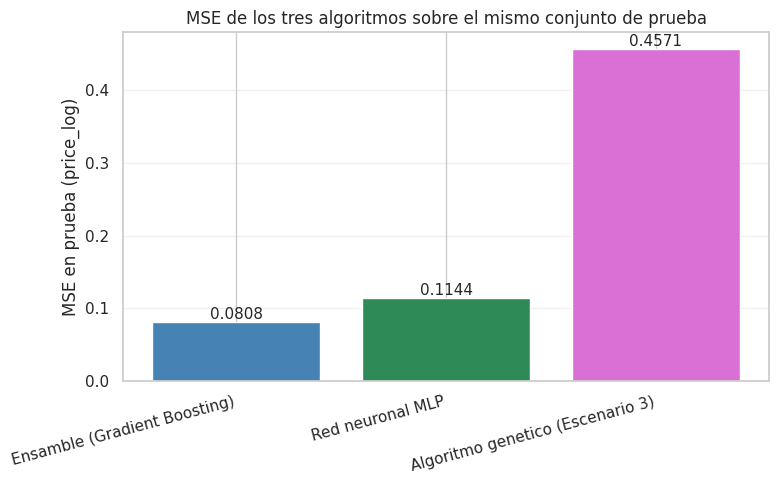

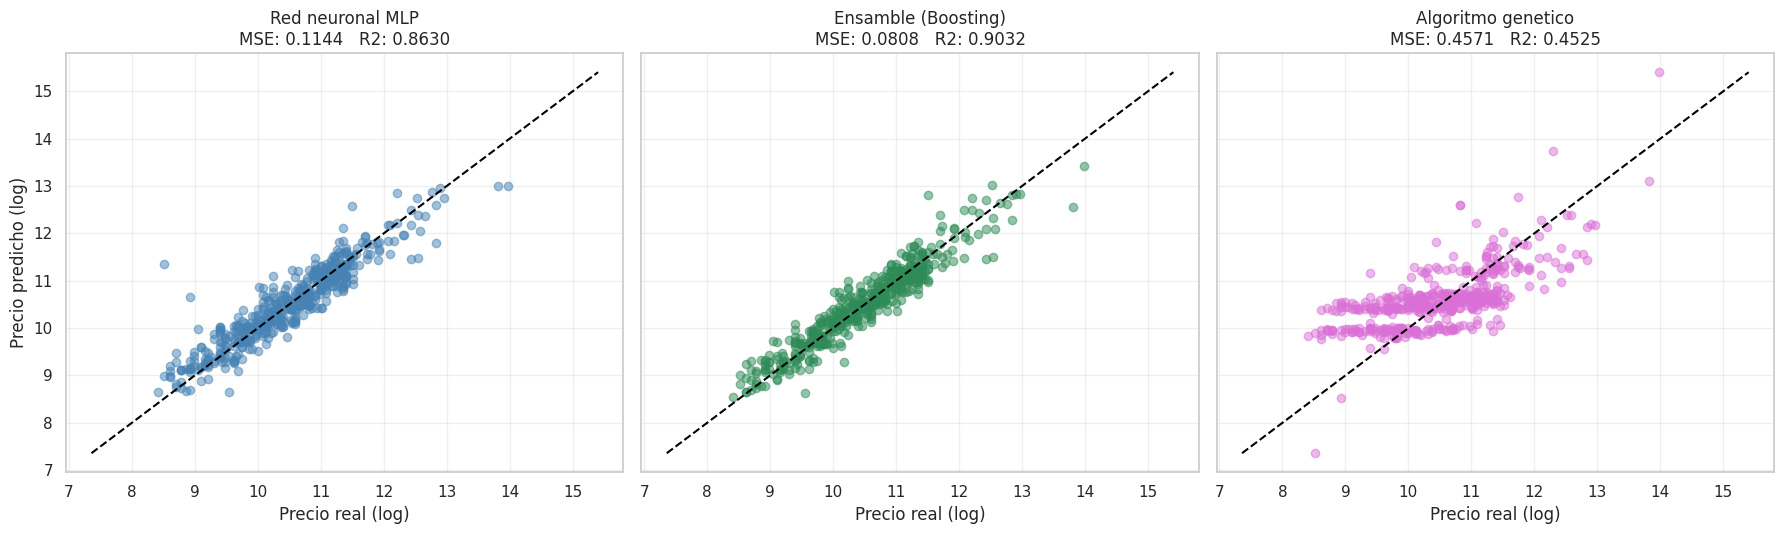

In [ ]:
# Grafica 1: MSE de los tres modelos

plt.figure(figsize=(8, 5))

colores = ['steelblue', 'seagreen', 'orchid']
barras = plt.bar(comparacion_final['Modelo'], comparacion_final['MSE'], color=colores)

for barra, valor in zip(barras, comparacion_final['MSE']):
    plt.text(barra.get_x() + barra.get_width() / 2, valor,
             f'{valor:.4f}', ha='center', va='bottom', fontsize=11)

plt.ylabel('MSE en prueba (price_log)')
plt.title('MSE de los tres algoritmos sobre el mismo conjunto de prueba')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# Grafica 2: real vs. predicho de los tres modelos

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)

modelos = [
    ('Red neuronal MLP', y_pred_mlp, 'steelblue'),
    ('Ensamble (Boosting)', y_pred_ens, 'seagreen'),
    ('Algoritmo genetico', y_pred_ga, 'orchid'),
]

limite_min = min(y_real.min(), min(p.min() for _, p, _ in modelos))
limite_max = max(y_real.max(), max(p.max() for _, p, _ in modelos))

for eje, (nombre, pred, color) in zip(axes, modelos):
    eje.scatter(y_real, pred, alpha=0.5, color=color)
    eje.plot([limite_min, limite_max], [limite_min, limite_max],
             linestyle='--', color='black')
    eje.set_title(f'{nombre}\nMSE: {mean_squared_error(y_real, pred):.4f}   '
                  f'R2: {r2_score(y_real, pred):.4f}')
    eje.set_xlabel('Precio real (log)')
    eje.grid(True, alpha=0.3)

axes[0].set_ylabel('Precio predicho (log)')
plt.tight_layout()
plt.show()


#### Tiempo de ejecucion

Se reentrena cada modelo con la misma configuracion y se cronometra con `time.time()`.


In [ ]:
# Tiempo de entrenamiento de los tres algoritmos
import time
from tensorflow.keras.models import clone_model

# MLP: misma arquitectura pero con los pesos sin entrenar
mlp_cron = clone_model(model)
mlp_cron.compile(optimizer='adam', loss='mse')

inicio = time.time()
mlp_cron.fit(X_train_scaled, y_train, validation_split=0.20, epochs=200,
             batch_size=32, callbacks=[early_stop], verbose=0)
t_mlp = time.time() - inicio

inicio = time.time()
modelo_boosting.fit(X_train_scaled, y_train)
t_ens = time.time() - inicio

inicio = time.time()
genetic_algorithm(generations=1000, X=X_train_ga,
                  y_real=y_train_ga, population_size=300)
t_ga = time.time() - inicio

print(f'\nRed neuronal MLP    : {t_mlp:6.2f} s')
print(f'Ensamble (Boosting) : {t_ens:6.2f} s')
print(f'Algoritmo genetico  : {t_ga:6.2f} s')


[INFO] Generacion  200  -  mejor MSE: 0.460038
[INFO] Generacion  400  -  mejor MSE: 0.465779
[INFO] Generacion  600  -  mejor MSE: 0.464047
[INFO] Generacion  800  -  mejor MSE: 0.464004
[INFO] Generacion 1000  -  mejor MSE: 0.462310

Red neuronal MLP    :  15.67 s
Ensamble (Boosting) :   0.47 s
Algoritmo genetico  :  16.55 s
